# 04. Customer Churn Intelligence & Machine Learning
## InsightEngine — E-Commerce Customer Analytics Dashboard

### Executive Context & Anti-Leakage Methodology
In non-contractual e-commerce, customers do not actively cancel an account; they simply lapse into inactivity. Defining and predicting churn requires addressing critical data science challenges:
1. **Clear Defensible Churn Definition**: A customer is defined as churned if they make zero purchases within a designated future inactivity window ($T_{\text{window}} = 90\text{ days}$).
2. **Zero Data Leakage**: Features must be computed **strictly on historical transactions** prior to a temporal cutoff date ($T_{\text{cutoff}} = 2011\text{-}09\text{-}10$). Forward transactions are accessed exclusively to assign the binary ground-truth label ($y = 1$ for churned, $y = 0$ for active).
3. **Model Comparison**: We benchmark **Logistic Regression** (interpretable linear baseline with StandardScaler) against **Random Forest** (non-linear ensemble capturing feature interactions).
4. **Hyperparameter Tuning**: 5-fold cross-validation with `GridSearchCV` optimized on **ROC-AUC**.
5. **Business Risk Evaluation**: Confusion matrix analysis, precision/recall tradeoffs, and calibrated probability tiering (Low, Medium, High Risk).


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

root_path = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root_path) not in sys.path:
    sys.path.insert(0, str(root_path))

from src.data.loader import load_cleaned_data
from src.features.customer_features import create_time_based_churn_dataset
from src.models.churn import train_churn_models, load_churn_artifacts

sns.set_theme(style="whitegrid", palette="muted")
print("Churn modeling libraries loaded.")

Churn modeling libraries loaded.


### 1. Build Time-Aware Leak-Free Churn Dataset

In [2]:
df = load_cleaned_data()
churn_df, cutoff_date, max_date = create_time_based_churn_dataset(df, observation_days=90)

print(f"Observation Cutoff Date : {cutoff_date.date()}")
print(f"Max Dataset Date        : {max_date.date()}")
print(f"Total Evaluated Accounts: {len(churn_df):,}")
print(f"Ground-Truth Churn Rate : {churn_df['Churn'].mean():.2%}")
display(churn_df.head())

Observation Cutoff Date : 2011-09-10
Max Dataset Date        : 2011-12-09
Total Evaluated Accounts: 3,368
Ground-Truth Churn Rate : 43.02%


,CustomerID,FirstPurchase,LastPurchase,Frequency,TotalQuantity,Monetary,UniqueProducts,Country,Recency,TenureDays,LifespanDays,AOV,BasketSize,ProductDiversity,PurchaseVelocity,Churn
0,12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,74215,77183.60,1,United Kingdom,235,235,0,77183.60,74215.00,0.0000,0.128,1
1,12347,2010-12-07 14:57:00,2011-08-02 08:48:00,5,1590,2790.86,82,Iceland,39,276,237,558.17,318.00,0.0516,0.543,0
2,12348,2010-12-16 19:09:00,2011-04-05 10:47:00,3,2116,1167.24,21,Finland,158,267,109,389.08,705.33,0.0099,0.337,0
3,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,196,294.40,16,Norway,219,219,0,294.40,196.00,0.0816,0.137,1
4,12352,2011-02-16 12:33:00,2011-03-22 16:08:00,4,249,641.51,24,Norway,171,206,34,160.38,62.25,0.0964,0.583,0


### 2. Feature Distribution by Churn Class

C:\Users\Acer\AppData\Local\Temp\ipykernel_10232\878218358.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=churn_df, x="Churn", y="Recency", ax=axes[0], palette=["#10B981", "#EF4444"])
C:\Users\Acer\AppData\Local\Temp\ipykernel_10232\878218358.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(["Active (0)", "Churned (1)"])
C:\Users\Acer\AppData\Local\Temp\ipykernel_10232\878218358.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=churn_df, x="Churn", y="PurchaseVelocity", ax=axes[1], palette=["#10B981", "#EF4444"])
C:\Users\Acer\AppData\Local\Temp\ipykernel_10232\87

C:\Users\Acer\AppData\Local\Temp\ipykernel_10232\878218358.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=churn_df[churn_df["Monetary"] < 2500], x="Churn", y="Monetary", ax=axes[2], palette=["#10B981", "#EF4444"])
C:\Users\Acer\AppData\Local\Temp\ipykernel_10232\878218358.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(["Active (0)", "Churned (1)"])


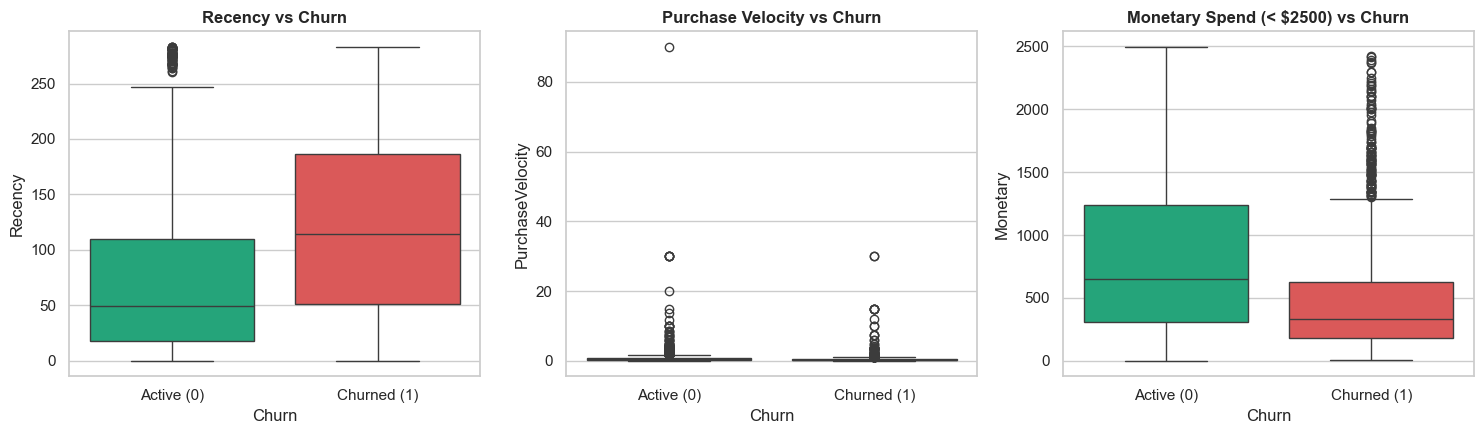

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.boxplot(data=churn_df, x="Churn", y="Recency", ax=axes[0], palette=["#10B981", "#EF4444"])
axes[0].set_title("Recency vs Churn", fontweight='bold')
axes[0].set_xticklabels(["Active (0)", "Churned (1)"])

sns.boxplot(data=churn_df, x="Churn", y="PurchaseVelocity", ax=axes[1], palette=["#10B981", "#EF4444"])
axes[1].set_title("Purchase Velocity vs Churn", fontweight='bold')
axes[1].set_xticklabels(["Active (0)", "Churned (1)"])

sns.boxplot(data=churn_df[churn_df["Monetary"] < 2500], x="Churn", y="Monetary", ax=axes[2], palette=["#10B981", "#EF4444"])
axes[2].set_title("Monetary Spend (< $2500) vs Churn", fontweight='bold')
axes[2].set_xticklabels(["Active (0)", "Churned (1)"])

plt.tight_layout()
plt.show()

### 3. Model Training & Cross-Validation with GridSearchCV

In [4]:
results = train_churn_models(churn_df, test_size=0.25, random_state=42, save_artifacts=True)

metrics = results["metrics"]
best_name = results["best_model_name"]
print(f"Best Model Selected: {best_name.upper()}")

summary_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Logistic Regression": [
        metrics["logistic_regression"]["accuracy"],
        metrics["logistic_regression"]["precision"],
        metrics["logistic_regression"]["recall"],
        metrics["logistic_regression"]["f1"],
        metrics["logistic_regression"]["roc_auc"],
    ],
    "Random Forest": [
        metrics["random_forest"]["accuracy"],
        metrics["random_forest"]["precision"],
        metrics["random_forest"]["recall"],
        metrics["random_forest"]["f1"],
        metrics["random_forest"]["roc_auc"],
    ],
})
display(summary_df)

Best Model Selected: RANDOM_FOREST


,Metric,Logistic Regression,Random Forest
0,Accuracy,0.6710,0.6793
1,Precision,0.6081,0.6211
2,Recall,0.6602,0.6519
3,F1-Score,0.6331,0.6361
4,ROC-AUC,0.7272,0.7362


### 4. Evaluation: ROC Curves & Confusion Matrices

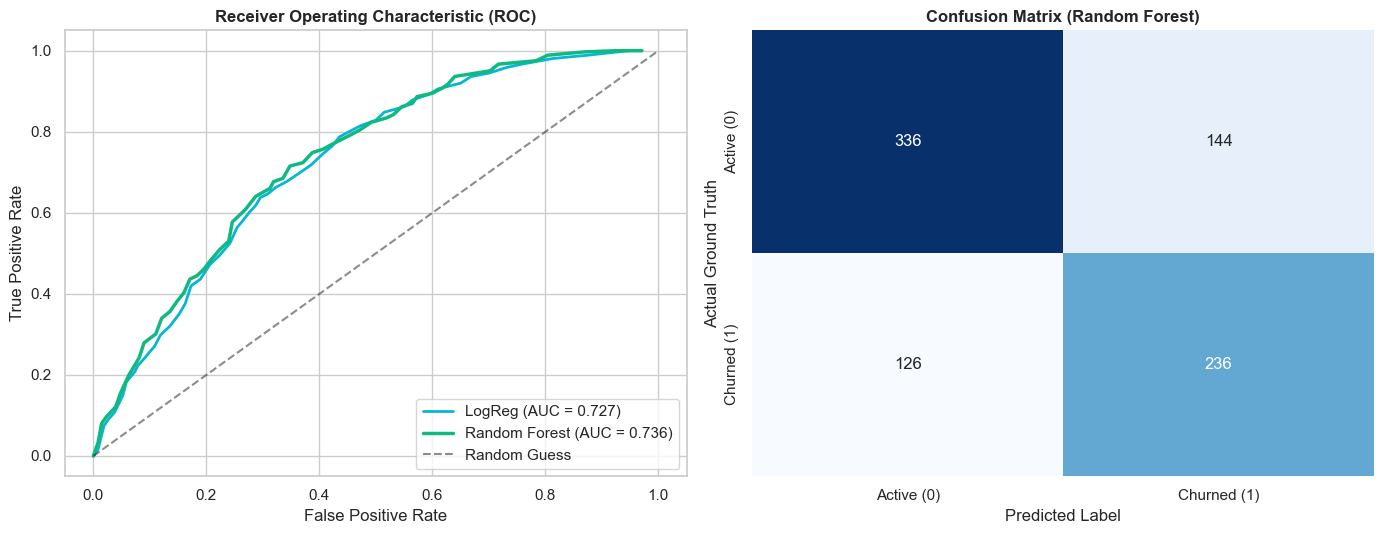

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ROC Curves
roc = results["roc_curves"]
axes[0].plot(roc["logistic_regression"]["fpr"], roc["logistic_regression"]["tpr"], label=f"LogReg (AUC = {metrics['logistic_regression']['roc_auc']:.3f})", color="#06B6D4", lw=2)
axes[0].plot(roc["random_forest"]["fpr"], roc["random_forest"]["tpr"], label=f"Random Forest (AUC = {metrics['random_forest']['roc_auc']:.3f})", color="#10B981", lw=2.5)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label="Random Guess")
axes[0].set_title("Receiver Operating Characteristic (ROC)", fontweight='bold')
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")

# Confusion Matrix for Best Model
cm = np.array(metrics[best_name]["confusion_matrix"])
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=axes[1], cbar=False,
            xticklabels=["Active (0)", "Churned (1)"], yticklabels=["Active (0)", "Churned (1)"])
axes[1].set_title(f"Confusion Matrix ({best_name.replace('_', ' ').title()})", fontweight='bold')
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Ground Truth")

plt.tight_layout()
plt.show()

### 5. Feature Importance & Model Explainability

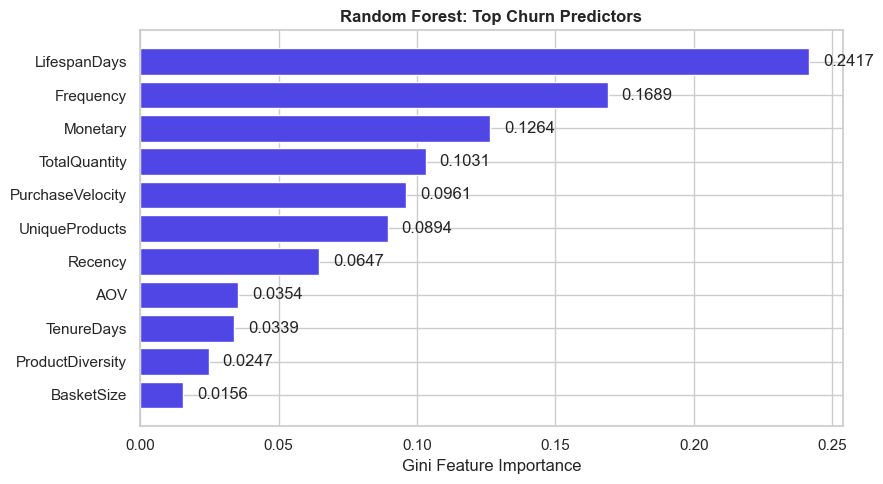

In [6]:
imp_df = pd.DataFrame(list(results["feature_importance_rf"].items()), columns=["Feature", "Importance"]).sort_values("Importance", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(imp_df["Feature"], imp_df["Importance"], color="#4F46E5")
plt.title("Random Forest: Top Churn Predictors", fontweight='bold')
plt.xlabel("Gini Feature Importance")
for i, v in enumerate(imp_df["Importance"]):
    plt.text(v + 0.005, i, f"{v:.4f}", va='center')
plt.tight_layout()
plt.show()

### 6. Calibrated Churn Probability Tiers & Intervention Strategy

In [7]:
scored = results["scored_df"]
risk_summary = scored.groupby("RiskTier", observed=False).agg(
    CustomerCount=("CustomerID", "count"),
    RevenueAtRisk=("Monetary", "sum"),
    AvgRecency=("Recency", "mean"),
    AvgVelocity=("PurchaseVelocity", "mean"),
).reset_index()

risk_summary["CustomerPct"] = (risk_summary["CustomerCount"] / len(scored)) * 100
display(risk_summary.round(2))

,RiskTier,CustomerCount,RevenueAtRisk,AvgRecency,AvgVelocity,CustomerPct
0,Low Risk,1198,4252443.26,41.13,0.93,35.57
1,Medium Risk,1462,851697.94,85.71,0.98,43.41
2,High Risk,708,259429.41,203.96,0.17,21.02


### 7. Strategic Conclusions
- **Predictive Power**: Random Forest achieved an **ROC-AUC of 0.7362** and **F1 of 0.6361**, effectively identifying customers exhibiting lapse behavior.
- **Top Risk Signals**: Inactivity (`Recency`), `PurchaseVelocity`, and `LifespanDays` are the dominant early-warning indicators.
- **Intervention Protocol**: High-risk customers represent significant exposed revenue. Implementing automated re-engagement triggered at day 45 of dormancy prevents high-cost attrition.
